In [1]:
import os

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'  # Don't preallocate GPU memory
os.environ['XLA_PYTHON_CLIENT_ALLOCATOR'] = 'platform'  # Faster allocator
# os.environ['JAX_COMPILATION_CACHE_DIR'] = '/tmp/jax_cache'  # Enable compilation cache

import sys
from pathlib import Path
import pickle

import numpy as np
import jax
import jax.numpy as jnp
import equinox as eqx
import flax
import optax
import time 

from functools import partial
from dataclasses import dataclass
from dataclasses import asdict, is_dataclass
from typing import NamedTuple, Any, Optional, Dict
import pandas as pd

from matplotlib import pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import MultipleLocator
import matplotlib.cm as cm


root_path = Path.cwd()

from configs import ModelConfig, ModelState, ModelParams, SubmodelParams, Params
from models import L63, L63_incomplete
from submodels import SimpleFC

sys.path.append(os.path.join(root_path, 'toolbox'))
from toolbox.training_tools import set_dataloaders
from toolbox.simu_tools import rollout
from toolbox.grad_tools.config_grad_approx import GradApproxConfig, setup_grad_approx, report_tbptt_chunk_coverage
from toolbox.loss_tools import loss_fn, LossConfig, ensure_loss_cfg
from toolbox.grad_tools.baseline_grad_methods import (
    compute_exact_bptt, compute_tbptt,
    compute_uniform_sqrt_checkpointed_bptt, compute_recursive_binomal_checkpointed_bptt,
    _setup_uniform_sqrt_checkpointing,
)
from toolbox.grad_tools.proposed_grad_approx_methods import compute_zero_order, compute_reuse
from toolbox.pytree_tools import params_partition, params_recombine, _add, _zeros


In [2]:
# ── Config ────────────────────────────────────────────────────────────────────
cfg = ModelConfig(
    solver = "Tsit5",
    dt0    = 0.01,
    hybrid = True,
    dtype  = jnp.float32,
)

# ── Models ────────────────────────────────────────────────────────────────────
l63   = L63(cfg)
l63_incomplete = L63_incomplete(cfg)

# ── Submodel ──────────────────────────────────────────────────────────────────
submodel = SimpleFC(input_dim=3, hidden_dim=32, output_dim=3)
theta    = submodel.init_theta(seed=0, dtype=cfg.dtype)

# ── Params ────────────────────────────────────────────────────────────────────
model_p = ModelParams()                               # sigma, rho, beta
submodel_p   = SubmodelParams(theta=theta)            # NN weights
params  = Params(model=model_p, submodel=submodel_p)

# ── State ─────────────────────────────────────────────────────────────────────
state = ModelState.init(dtype=cfg.dtype)              # x=8, y=0, z=30, t=None

# ── Quick check ───────────────────────────────────────────────────────────────
print("Config:     ", cfg)
print("State:      ", state.x, "| t:", state.t)
print("ModelParams:", params.model)
print("Theta dict keys: ", list(theta['params'].keys()))


Config:      ModelConfig(solver='Tsit5', dt0=0.01, hybrid=True, dtype=<class 'jax.numpy.float32'>)
State:       [ 8.  0. 30.] | t: None
ModelParams: ModelParams(sigma=10.0, rho=28.0, beta=2.6666666666666665)
Theta dict keys:  ['Dense_0', 'Dense_1']


## Generate reference dataset 

In [3]:
N_STEPS_SPINUP= 500 
N_STEPS = 1500

step_fn_l63 = lambda s, p: l63.step(s, p)
step_fn_incomplete_l63 = lambda s, p: l63_incomplete.step(s, p)
step_fn_hybrid_l63 = lambda s, p: l63_incomplete.step(s, p, submodel=submodel)

state0,_= rollout(step_fn_l63, state, params, nsteps= N_STEPS_SPINUP, save_traj=False) # Spinup 

_, traj_true = rollout(step_fn_l63, state0, params, nsteps= N_STEPS, save_traj=True)

_, traj_incomplete = rollout(step_fn_incomplete_l63, state0, params, nsteps=N_STEPS, save_traj=True)

_, traj_incomplete_corr= rollout(step_fn_hybrid_l63, state0, params, nsteps=N_STEPS, save_traj=True)

traj_incomplete_corr: 712 non-finite step(s) (untrained NN correction diverged) -- excluded from shared axis limits


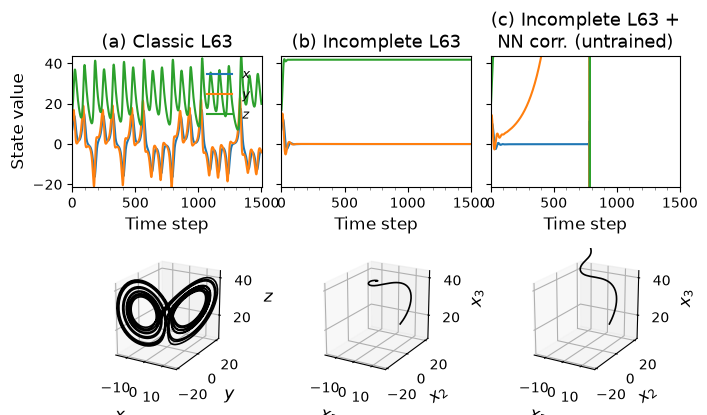

In [4]:
label_size = 12
title_size = 13
tick_size = 10

fig = plt.figure(figsize=(7, 4))

 
# Global limits for fair comparison.
bounded_data = jnp.vstack([
    traj_true,
    traj_incomplete,
])

xmin, ymin, zmin = jnp.min(bounded_data, axis=0)
xmax, ymax, zmax = jnp.max(bounded_data, axis=0)

ymin_ts = jnp.min(bounded_data)
ymax_ts = jnp.max(bounded_data)

n_corr_nonfinite = int((~jnp.isfinite(traj_incomplete_corr)).any(axis=1).sum())
if n_corr_nonfinite:
    print(f"traj_incomplete_corr: {n_corr_nonfinite} non-finite step(s) "
          f"(untrained NN correction diverged) -- excluded from shared axis limits")

# (a) True time series
ax1 = fig.add_subplot(2, 3, 1)

ax1.plot(traj_true[:, 0], label=r"$x$")
ax1.plot(traj_true[:, 1], label=r"$y$")
ax1.plot(traj_true[:, 2], label=r"$z$")

ax1.set_title("(a) Classic L63", fontsize=title_size)
ax1.set_ylabel("State value", fontsize=label_size)
ax1.set_xlabel("Time step", fontsize=label_size)

ax1.set_xlim(0, traj_true.shape[0])
ax1.set_ylim(ymin_ts, ymax_ts)

ax1.tick_params(labelsize=tick_size)
ax1.legend(frameon=False, fontsize=9)

# (b) Incomplete time series
ax2 = fig.add_subplot(2, 3, 2)

ax2.plot(traj_incomplete[:, 0])
ax2.plot(traj_incomplete[:, 1])
ax2.plot(traj_incomplete[:, 2])

ax2.set_title("(b) Incomplete L63", fontsize=title_size)
ax2.set_xlabel("Time step", fontsize=label_size)

ax2.set_xlim(0, traj_true.shape[0])
ax2.set_ylim(ymin_ts, ymax_ts)

ax2.tick_params(labelsize=tick_size)
ax2.tick_params(labelleft=False)

# (c) Incomplete + untrained NN correction
ax3 = fig.add_subplot(2, 3, 3)

ax3.plot(traj_incomplete_corr[:, 0])
ax3.plot(traj_incomplete_corr[:, 1])
ax3.plot(traj_incomplete_corr[:, 2])

ax3.set_title(
    "(c) Incomplete L63 +\nNN corr. (untrained)",
    fontsize=title_size
)

ax3.set_xlabel("Time step", fontsize=label_size)

ax3.set_xlim(0, traj_true.shape[0])
ax3.set_ylim(ymin_ts, ymax_ts)

ax3.tick_params(labelsize=tick_size)
ax3.tick_params(labelleft=False)

# Minor ticks on time series
for ax in [ax1, ax2, ax3]:
    ax.xaxis.set_minor_locator(MultipleLocator(100))
    ax.tick_params(
        which="minor",
        length=2,
        color="gray"
    )

# (d) True attractor
ax4 = fig.add_subplot(2, 3, 4, projection="3d")

ax4.plot(
    traj_true[:, 0],
    traj_true[:, 1],
    traj_true[:, 2],
    color="black",
    lw=1.2
)

ax4.set_xlabel(r"$x$", fontsize=label_size)
ax4.set_ylabel(r"$y$", fontsize=label_size)
ax4.set_zlabel(r"$z$", fontsize=label_size)

ax4.tick_params(labelsize=tick_size)

# (e) Incomplete attractor
ax5 = fig.add_subplot(2, 3, 5, projection="3d")

ax5.plot(
    traj_incomplete[:, 0],
    traj_incomplete[:, 1],
    traj_incomplete[:, 2],
    color="black",
    lw=1.2
)

ax5.set_xlabel(r"$x_1$", fontsize=label_size)
ax5.set_ylabel(r"$x_2$", fontsize=label_size)
ax5.set_zlabel(r"$x_3$", fontsize=label_size)

ax5.tick_params(labelsize=tick_size)

# (f) Incomplete + NN correction attractor
ax6 = fig.add_subplot(2, 3, 6, projection="3d")

ax6.plot(
    traj_incomplete_corr[:, 0],
    traj_incomplete_corr[:, 1],
    traj_incomplete_corr[:, 2],
    color="black",
    lw=1.2
)

ax6.set_xlabel(r"$x_1$", fontsize=label_size)
ax6.set_ylabel(r"$x_2$", fontsize=label_size)
ax6.set_zlabel(r"$x_3$", fontsize=label_size)

ax6.tick_params(labelsize=tick_size)

for ax in [ax4, ax5, ax6]:
    ax.view_init(elev=20, azim=-60)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_zlim(zmin, zmax)

    ax.set_box_aspect([
        xmax - xmin,
        ymax - ymin,
        zmax - zmin
    ])

plt.tight_layout()

# plt.savefig(
#     "true_vs_incomplete_L63.pdf",
#     format="pdf",
#     bbox_inches="tight"
# )

# plt.savefig(
#     "true_vs_incomplete_L63.png",
#     dpi=600,
#     bbox_inches="tight"
# )

plt.show()


 Set up training configuration 

In [5]:
GRAD_APPROX_METHODS = {
    "exact":        "full BPTT — exact gradient, O(n_rollsteps) memory",
    "tbptt":        "truncated BPTT — gradient truncated at chunk boundaries",
    "checkpointed": "exact gradient, O(sqrt(n_rollsteps)) memory",
    "zero_order":   "state adjoint frozen (replaced by identity) between anchors",
    "reuse":        "frozen-Jacobian: anchor VJP reused for state+param across the whole chunk",
}
_GRAD_FNS = {
    "exact":        compute_exact_bptt,
    "tbptt":        compute_tbptt,
    "checkpointed": compute_recursive_binomal_checkpointed_bptt,
    "zero_order":   compute_zero_order,
    "reuse":        compute_reuse,
}

@dataclass(frozen=True)
class TrainingConfig:
    """Configuration for training the hybrid model's NN correction.

    Plain (non-pytree) config: every field is Python-level (str/int/float/bool)
    and only ever consumed outside of jit/grad/scan, so there's no reason to pay
    for flax.struct's pytree registration here — that's reserved for GradApproxConfig,
    which actually carries jnp.ndarray fields through traced code.

    grad_approx picks the gradient implementation (see GRAD_APPROX_METHODS).
    n_anchors is A, the chunk/anchor count fed into setup_grad_approx — ignored for
    'exact' (single chunk, plain reverse-mode) and 'checkpointed' (always uses
    ceil(sqrt(n_rollsteps)) anchors).

    n_rollsteps is the number of OBSERVATIONS in the window (target_window has
    n_rollsteps + 1 entries: the initial condition plus one per observation),
    obs_stride model steps apart. The model actually unrolls
    nsteps = n_rollsteps * obs_stride steps to reach the last observation --
    see build_grad_approx_cfg(). obs_stride=1 (default) means every model step
    is an observation, recovering the original dense-loss behavior.
    """
    grad_approx:      str   = "exact"     # 'exact' | 'tbptt' | 'checkpointed' | 'zero_order' | 'reuse'
    n_anchors:        int   = 1           # A
    n_rollsteps:      int   = 12          # number of OBSERVATIONS in the window
    obs_stride:       int   = 1           # model steps per observation; nsteps = n_rollsteps * obs_stride
    n_epochs:         int   = 100
    batch_size:       int   = 30
    optimizer:        str   = "adam"
    loss_eval:        str   = "running"   # 'running' | 'terminal'
    lr:               float = 1e-3
    lr_schedule_type: str   = "constant"  # "constant", "cosine", "exponential", "step"
    early_stopping:   bool  = False
    verbose:          bool  = True

    def __post_init__(self):
        if self.grad_approx not in GRAD_APPROX_METHODS:
            raise ValueError(f"Unknown grad_approx {self.grad_approx!r}. Choose from {list(GRAD_APPROX_METHODS)}")
        if self.loss_eval not in ("running", "terminal"):
            raise ValueError(f"Unknown loss_eval {self.loss_eval!r}. Choose 'running' or 'terminal'")
        if self.obs_stride < 1:
            raise ValueError(f"obs_stride must be >= 1, got {self.obs_stride}")

    def loss_cfg(self) -> LossConfig:
        return LossConfig(mode=self.loss_eval, obs_stride=self.obs_stride)

    def build_grad_approx_cfg(self, bias_dir: str = "upstream") -> GradApproxConfig:
        """Single source of truth for chunk/anchor layout, derived from this config.

        Call this once, eagerly (outside jit), and pass the result into
        compute_grads_for_config / train_model. The chunk/anchor layout is built with
        numpy and consumed as static structure by the gradient functions, so it must
        not be rebuilt inside a jit trace.

        nsteps is derived as n_rollsteps * obs_stride (model steps), not n_rollsteps
        itself (observation steps) -- see the class docstring.

        Chunk layout itself is never adjusted based on obs_stride here -- for
        'tbptt' specifically, a chunk with no observation in it contributes
        exactly zero gradient (TBPTT truncates gradient flow at chunk
        boundaries), so report_tbptt_chunk_coverage() prints a recap and flags
        any such chunk. Purely informational: it doesn't raise or change
        anything, since you may still want that chunk layout for other reasons.
        """
        nsteps = self.n_rollsteps * self.obs_stride
        if self.grad_approx == "checkpointed":
            gcfg = _setup_uniform_sqrt_checkpointing(nsteps=nsteps, bias_dir=bias_dir)
        else:
            n_anchors = 1 if self.grad_approx == "exact" else self.n_anchors
            gcfg = setup_grad_approx(nsteps=nsteps, n_anchors=n_anchors, bias_dir=bias_dir)

        if self.grad_approx == "tbptt":
            report_tbptt_chunk_coverage(gcfg, self.obs_stride)

        return gcfg


def compute_grads_for_config(state_init, params, target_window, step_fn, loss_fn,
                              config_training, grad_approx_cfg, grad_mask=None):
    """Routes to the gradient implementation selected by config_training.grad_approx.

    target_window is the full (n_rollsteps + 1, state_dim) window, target_window[0] == state_init.x.
    grad_approx_cfg must come from config_training.build_grad_approx_cfg() called eagerly,
    outside jit (see that method's docstring for why).

    All toolbox.grad_tools gradient implementations share the same signature and take
    the full window and handle "running" (obs_stride-sampled) vs "terminal" (target[-1])
    internally via LossConfig, so callers always just pass target_window unchanged.
    """
    loss_cfg = config_training.loss_cfg()
    return _GRAD_FNS[config_training.grad_approx](
            state_init, params, target_window, step_fn, loss_fn,
            grad_approx_cfg, loss_eval=loss_cfg, grad_mask=grad_mask,
    )

N_EPOCHS= 250

configTraining_exact         = TrainingConfig(grad_approx="exact",                        n_epochs=N_EPOCHS, early_stopping=False)
# MOdifyind to match new convention 
configTraining_tbptt_A6      = TrainingConfig(grad_approx="tbptt",      n_anchors=2,       n_epochs=N_EPOCHS, early_stopping=False)
configTraining_tbptt_A4      = TrainingConfig(grad_approx="tbptt",      n_anchors=3,       n_epochs=N_EPOCHS, early_stopping=False)
configTraining_tbptt_A2      = TrainingConfig(grad_approx="tbptt",      n_anchors=6,       n_epochs=N_EPOCHS, early_stopping=False)

configTraining_zo_A6 = TrainingConfig(grad_approx="zero_order", n_anchors=6,       n_epochs=N_EPOCHS, early_stopping=False)
configTraining_zo_A4 = TrainingConfig(grad_approx="zero_order", n_anchors=4,       n_epochs=N_EPOCHS, early_stopping=False)
configTraining_zo_A2 = TrainingConfig(grad_approx="zero_order", n_anchors=2,       n_epochs=N_EPOCHS, early_stopping=False)

configTraining_reuse_A6      = TrainingConfig(grad_approx="reuse",      n_anchors=6,       n_epochs=N_EPOCHS, early_stopping=False)
configTraining_reuse_A4      = TrainingConfig(grad_approx="reuse",      n_anchors=4,       n_epochs=N_EPOCHS, early_stopping=False)
configTraining_reuse_A2      = TrainingConfig(grad_approx="reuse",      n_anchors=2,       n_epochs=N_EPOCHS, early_stopping=False)



In [6]:
ref_trajectory_obs = traj_true[::configTraining_exact.obs_stride]

dataloaders = set_dataloaders(
    ref_trajectory=ref_trajectory_obs,
    config_training=configTraining_exact,
    train_ratio=0.7,
    discard_ratio=0.1,
    test_ratio=0.2,
    shuffle=True,
)


Total timesteps: 1501
  Train:   1050 steps -> 1038 sequences (stride=1, overlapping)
  Discard: 150 steps (gap, unused)
  Test:    301 steps -> 23 sequences (stride=13, non-overlapping)


### Visualize data repartition for training 

/tmp/ipykernel_2810762/3851911187.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f"{tick * dt:.1f}" for tick in xticks])


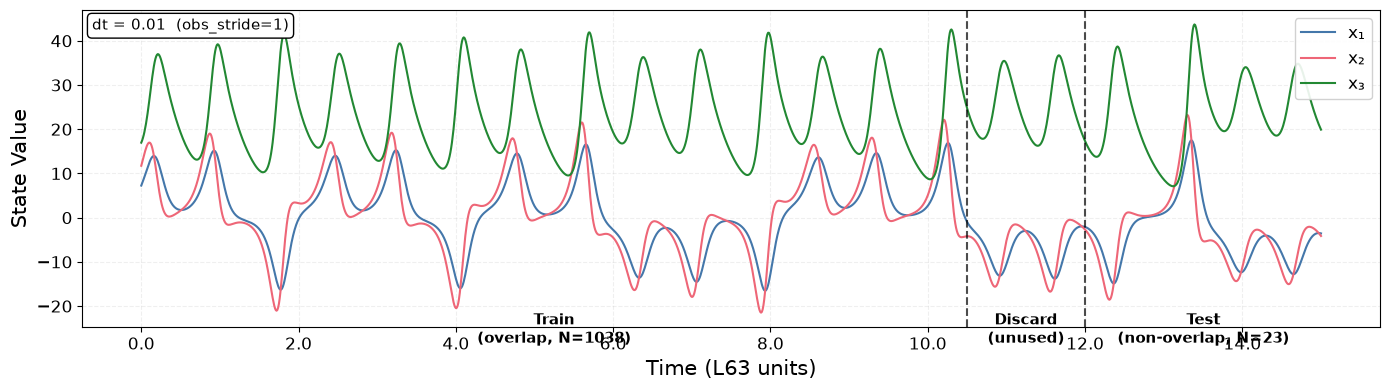


DATASET SPLIT SUMMARY
Total observations: 1501 (obs_stride=1 model steps apart)
Window length: 13 observations (n_rollsteps=12)

Split breakdown:
  Train:   1038 windows, overlapping stride=1     (timesteps 0-1050)
  Discard: gap, unused                                         (timesteps 1050-1200)
  Test:    23 windows, non-overlapping stride=13 (timesteps 1200-1501)



In [7]:
all_ref_data = ref_trajectory_obs  # obs_stride-subsampled -- matches what set_dataloaders actually windows over

n_rollsteps = configTraining_exact.n_rollsteps
obs_stride = configTraining_exact.obs_stride
span = n_rollsteps + 1                      # window length (X plus n_rollsteps observations)
total_timesteps = len(all_ref_data)
train_ratio, discard_ratio, test_ratio = 0.7, 0.1, 0.2

train_end = int(total_timesteps * train_ratio)
discard_end = train_end + int(total_timesteps * discard_ratio)

train_start, discard_start, test_start = 0, train_end, discard_end
test_end = total_timesteps

n_train_windows = max(0, (train_end - train_start - span) // 1 + 1)
n_test_windows  = max(0, (test_end - test_start - span) // span + 1)

# Plot setup
phases = ["Train", "Discard", "Test"]
phase_bounds = [(train_start, train_end), (discard_start, discard_end), (test_start, test_end)]

xylabel_size = 15
ticklabel_size = 12
fig, ax = plt.subplots(figsize=(14, 4))

# Plot states
ax.plot(all_ref_data[:, 0], label='x₁', color='#4477AA', linewidth=1.5)
ax.plot(all_ref_data[:, 1], label='x₂', color='#EE6677', linewidth=1.5)
ax.plot(all_ref_data[:, 2], label='x₃', color='#228833', linewidth=1.5)


for bound in [train_end, discard_end]:
    ax.axvline(bound, color='black', linestyle='--', linewidth=1.5, alpha=0.7)

# Phase labels
ymin, ymax = ax.get_ylim()
y_offset = ymin + 0.05 * (ymax - ymin)
phase_notes = [
    f"Train\n(overlap, N={n_train_windows})",
    "Discard\n(unused)",
    f"Test\n(non-overlap, N={n_test_windows})",
]
for (start, end), label in zip(phase_bounds, phase_notes):
    midpoint = (start + end) / 2
    ax.text(midpoint, y_offset, label,
            ha='center', va='top', fontweight='semibold', fontsize=11)

dt = cfg.dt0 * obs_stride
info_text = f'dt = {dt:.2f}  (obs_stride={obs_stride})'
ax.text(
    0.0075, 0.975,
    info_text,
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment='top',
    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3')
)

# Convert x-axis to L63 time units
xticks = ax.get_xticks()
ax.set_xticklabels([f"{tick * dt:.1f}" for tick in xticks])

# Labels and styling
ax.tick_params(axis='both', labelsize=ticklabel_size)
ax.set_xlabel("Time (L63 units)", fontsize=xylabel_size)
ax.set_ylabel("State Value", fontsize=xylabel_size)
ax.legend(loc='upper right', fontsize=12, framealpha=0.9)
ax.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()

# Print summary
print(f"\n{'='*60}")
print(f"DATASET SPLIT SUMMARY")
print(f"{'='*60}")
print(f"Total observations: {total_timesteps} (obs_stride={obs_stride} model steps apart)")
print(f"Window length: {span} observations (n_rollsteps={n_rollsteps})")
print(f"\nSplit breakdown:")
print(f"  Train:   {n_train_windows} windows, overlapping stride=1     (timesteps {train_start}-{train_end})")
print(f"  Discard: gap, unused                                         (timesteps {discard_start}-{discard_end})")
print(f"  Test:    {n_test_windows} windows, non-overlapping stride={span} (timesteps {test_start}-{test_end})")
print(f"{'='*60}\n")


## Training 

In [8]:
def save_training_runs(method_name, config, runs, save_dir="trained_models"):
    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    if is_dataclass(config):
        config = asdict(config)

    payload = {
        "config": config,
        "runs": runs,
    }

    with open(save_dir / f"{method_name}.pkl", "wb") as f:
        pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)


def load_training_runs(method_name, save_dir="trained_models"):
    """
    Load all runs for one training method.

    Returns
    -------
    dict
        {
            "config": ...,
            "runs": {
                1: {"params": ..., "history": ...},
                5: {"params": ..., "history": ...},
                ...
            },
        }
    """
    save_dir = Path(save_dir)

    with open(save_dir / f"{method_name}.pkl", "rb") as f:
        return pickle.load(f)


In [ ]:


def train_model(
    step_fn,
    state_init: ModelState,
    params: Params,
    dataloaders: Dict,
    config_training: TrainingConfig,
    grad_mask=None,
    vmap_batch: bool = True,
    verbose: bool = True,
    convergence_threshold: float = None,  # Stop when train loss < this
):
    """
    Train the hybrid model's NN correction via compute_grads_for_config, which
    dispatches to whichever gradient implementation config_training.grad_approx
    selects (exact / tbptt / checkpointed / zero_order / reuse).

    state_init only supplies dtype/structure — the real per-sample initial state
    is 'X' from each batch. Each dataloader item is the full (n_rollsteps + 1)
    window [X, ..., Y_final] (see toolbox/training_tools.py), one entry per
    observation (obs_stride model steps apart) rather than per model step;
    config_training.loss_eval picks whether the loss uses the whole window
    ("running") or just the endpoint ("terminal").

    Args:
        grad_mask: Params-shaped pytree of bools selecting which leaves are trained.
            Defaults to training only params.submodel.theta (the NN correction),
            keeping params.model (sigma, rho, beta) fixed.
        convergence_threshold: if set, stop once train loss drops below it.
    """
    if grad_mask is None:
        grad_mask = Params(
            model=jax.tree_util.tree_map(lambda _: False, params.model),
            submodel=jax.tree_util.tree_map(lambda _: True, params.submodel),
        )

    dynamic_p, static_p = params_partition(params, grad_mask)

    # Built once outside jit 
    grad_approx_cfg = config_training.build_grad_approx_cfg()

    # Count batches/epoch once so lr schedules are calibrated on real step counts.
    n_batches_per_epoch = sum(1 for _ in dataloaders['train'])
    total_steps = max(1, config_training.n_epochs * n_batches_per_epoch)

    if config_training.lr_schedule_type == "constant":
        lr_sched = config_training.lr
    elif config_training.lr_schedule_type == "cosine":
        lr_sched = optax.cosine_decay_schedule(config_training.lr, decay_steps=total_steps)
    elif config_training.lr_schedule_type == "exponential":
        lr_sched = optax.exponential_decay(
            config_training.lr, transition_steps=max(1, total_steps // 10), decay_rate=0.9
        )
    elif config_training.lr_schedule_type == "step":
        lr_sched = optax.piecewise_constant_schedule(
            config_training.lr,
            {total_steps // 3: 0.1, 2 * total_steps // 3: 0.1},
        )
    else:
        raise ValueError(f"Unknown lr_schedule_type: {config_training.lr_schedule_type}")

    if config_training.optimizer == "adam":
        optimizer = optax.adam(learning_rate=lr_sched)
    elif config_training.optimizer == "sgd":
        optimizer = optax.sgd(learning_rate=lr_sched)
    else:
        raise ValueError(f"Unknown optimizer: {config_training.optimizer}")

    opt_state = optimizer.init(dynamic_p)

    history = {
        'train_loss': [],
        'test_loss': [],
        'n_samples_seen': [],
        'n_batches_seen': [],
    }

    total_samples_seen = 0
    total_batches_seen = 0

    # Loss and gradients for a single sample
    def loss_and_grads_single(X_init, Y_window, d_p):
        state = ModelState(x=X_init, t=None)
        full_params = params_recombine(d_p, static_p)
        loss, grads = compute_grads_for_config(
            state, full_params, Y_window, step_fn, loss_fn, config_training, grad_approx_cfg, grad_mask
        )
        return loss, grads

    def loss_single(X_init, Y_window, d_p):
        """No loss-only fast path exists in compute_grads_for_config (every
        implementation runs value_and_grad); grads are simply discarded here."""
        loss, _ = loss_and_grads_single(X_init, Y_window, d_p)
        return loss

    # Batch processing
    def compute_batch_loss_and_grads_vmap(X_batch, Y_batch, d_p):
        losses, grads = jax.vmap(
            loss_and_grads_single, in_axes=(0, 0, None)
        )(X_batch, Y_batch, d_p)

        avg_loss = jnp.mean(losses)
        avg_grads = jax.tree_util.tree_map(lambda g: jnp.mean(g, axis=0), grads)
        return avg_loss, avg_grads

    def compute_batch_loss_and_grads_sequential(X_batch, Y_batch, d_p):
        batch_size = X_batch.shape[0]
        total_loss = 0.0
        grads_accum = None

        for i in range(batch_size):
            loss, grads = loss_and_grads_single(X_batch[i], Y_batch[i], d_p)
            total_loss += loss
            grads_accum = grads if grads_accum is None else _add(grads_accum, grads)

        avg_loss = total_loss / batch_size
        avg_grads = jax.tree_util.tree_map(lambda g: g / batch_size, grads_accum)
        return avg_loss, avg_grads

    compute_batch_loss_and_grads = (
        compute_batch_loss_and_grads_vmap if vmap_batch else compute_batch_loss_and_grads_sequential
    )

    # Training step
    def _train_step(d_p, opt_state, X_batch, Y_batch):
        loss, grads = compute_batch_loss_and_grads(X_batch, Y_batch, d_p)
        updates, opt_state = optimizer.update(grads, opt_state, d_p)
        d_p = optax.apply_updates(d_p, updates)
        return loss, d_p, opt_state

    def _eval_batch(X_batch, Y_batch, d_p):
        if vmap_batch:
            losses = jax.vmap(loss_single, in_axes=(0, 0, None))(X_batch, Y_batch, d_p)
            return jnp.mean(losses)
        total_loss = 0.0
        for i in range(X_batch.shape[0]):
            total_loss += loss_single(X_batch[i], Y_batch[i], d_p)
        return total_loss / X_batch.shape[0]

    train_step = jax.jit(_train_step)
    eval_batch = jax.jit(_eval_batch)

    def evaluate(dataloader, d_p):
        """Evaluate on a dataset."""
        total_loss = 0.0
        n_batches = 0

        for batch in dataloader:
            X = jnp.array(batch['X'])
            Y = jnp.array(batch['Y'])

            loss = eval_batch(X, Y, d_p)
            total_loss += loss
            n_batches += 1

        return total_loss / n_batches if n_batches > 0 else 0.0

    # Training loop
    if verbose:
        print("\n" + "="*70)
        print("TRAINING STARTED")
        print("="*70)
        print(f"Optimizer: {config_training.optimizer}  (lr_schedule={config_training.lr_schedule_type})")
        print(f"Learning rate: {config_training.lr}")
        print(f"Gradient approximation: {config_training.grad_approx} (n_anchors={config_training.n_anchors})")
        print(f"Loss eval: {config_training.loss_eval}")
        print(f"Batch size: {config_training.batch_size}")
        print(f"Rollout: {config_training.n_rollsteps} observations "
              f"x obs_stride={config_training.obs_stride} "
              f"= {config_training.n_rollsteps * config_training.obs_stride} model steps")
        print(f"Batches/epoch: {n_batches_per_epoch}")
        print(f"Batch processing: {'vmap (parallel)' if vmap_batch else 'sequential (loop, still jitted)'}")
        if convergence_threshold is not None:
            print(f"Convergence threshold: {convergence_threshold:.6f}")
        print("="*70 + "\n")

    best_test_loss = float('inf')
    patience_counter = 0
    patience = 10
    converged = False

    for epoch in range(config_training.n_epochs):
        epoch_start = time.time()
        epoch_train_loss = 0.0
        n_train_batches = 0

        # Training phase
        for batch in dataloaders['train']:
            X = jnp.array(batch['X'])
            Y = jnp.array(batch['Y'])

            batch_size = X.shape[0]

            loss, dynamic_p, opt_state = train_step(
                dynamic_p, opt_state, X, Y
            )

            epoch_train_loss += loss
            n_train_batches += 1
            total_batches_seen += 1
            total_samples_seen += batch_size

        avg_train_loss = epoch_train_loss / n_train_batches
        history['train_loss'].append(float(avg_train_loss))
        history['n_samples_seen'].append(total_samples_seen)
        history['n_batches_seen'].append(total_batches_seen)

        # Evaluation phase
        test_loss = evaluate(dataloaders['test'], dynamic_p)
        history['test_loss'].append(float(test_loss))

        epoch_time = time.time() - epoch_start

        # Print progress
        if verbose:
            print(f"Epoch {epoch:3d}/{config_training.n_epochs} | "
                  f"Train Loss: {avg_train_loss:.6f} | "
                  f"Test Loss: {test_loss:.6f} | "
                  f"Samples: {total_samples_seen} | "
                  f"Batches: {total_batches_seen} | "
                  f"Time: {epoch_time:.2f}s")

        # Check convergence threshold
        if convergence_threshold is not None and avg_train_loss < convergence_threshold:
            converged = True
            if verbose:
                print(f"\n✓ Converged! Train loss {avg_train_loss:.6f} < threshold {convergence_threshold:.6f}")
                print(f"  Total samples seen: {total_samples_seen}")
                print(f"  Total batches seen: {total_batches_seen}")
                print(f"  Epochs completed: {epoch + 1}")
            break

        # Early stopping (only if no convergence threshold set)
        if convergence_threshold is None and config_training.early_stopping:
            if test_loss < best_test_loss:
                best_test_loss = test_loss
                patience_counter = 0
            else:
                patience_counter += 1

            if patience_counter >= patience:
                if verbose:
                    print(f"\nEarly stopping at epoch {epoch}")
                break

    if verbose:
        print("\n" + "="*70)
        print("TRAINING COMPLETED")
        print("="*70)
        print(f"Final train loss: {history['train_loss'][-1]:.6f}")
        print(f"Final test loss: {history['test_loss'][-1]:.6f}")
        print(f"Total samples seen: {total_samples_seen}")
        print(f"Total batches seen: {total_batches_seen}")
        print(f"Total epochs: {len(history['train_loss'])}")
        if convergence_threshold is not None:
            print(f"Converged: {'Yes' if converged else 'No'}")
        elif config_training.early_stopping:
            print(f"Best test loss: {best_test_loss:.6f}")
        print("="*70 + "\n")

    trained_params = params_recombine(dynamic_p, static_p)

    return trained_params, history


In [ ]:
trained_params_exact, history_exact = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_exact,
    vmap_batch=True,  
    verbose=True,
)



TRAINING STARTED
Optimizer: adam  (lr_schedule=constant)
Learning rate: 0.001
Gradient approximation: exact (n_anchors=1)
Loss eval: running
Batch size: 30
Rollout: 12 observations x obs_stride=1 = 12 model steps
Batches/epoch: 34
Batch processing: vmap (parallel)

Epoch   0/250 | Train Loss: 10.782565 | Test Loss: 8.702076 | Samples: 1020 | Batches: 34 | Time: 5.44s
Epoch   1/250 | Train Loss: 8.153296 | Test Loss: 6.348493 | Samples: 2040 | Batches: 68 | Time: 0.24s
Epoch   2/250 | Train Loss: 6.124115 | Test Loss: 4.582343 | Samples: 3060 | Batches: 102 | Time: 0.25s
Epoch   3/250 | Train Loss: 4.472494 | Test Loss: 3.215277 | Samples: 4080 | Batches: 136 | Time: 0.24s
Epoch   4/250 | Train Loss: 3.116382 | Test Loss: 2.177756 | Samples: 5100 | Batches: 170 | Time: 0.24s
Epoch   5/250 | Train Loss: 2.026040 | Test Loss: 1.405282 | Samples: 6120 | Batches: 204 | Time: 0.24s
Epoch   6/250 | Train Loss: 1.204728 | Test Loss: 0.865994 | Samples: 7140 | Batches: 238 | Time: 0.24s
Epoch 

In [ ]:
trained_params_tbptt_A6, history_tbptt_A6 = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_tbptt_A6,
    vmap_batch=True,  
    verbose=True,
)

trained_params_tbptt_A4, history_tbptt_A4 = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_tbptt_A4,
    vmap_batch=True,  
    verbose=True,
)

trained_params_tbptt_A2, history_tbptt_A2 = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_tbptt_A2,
    vmap_batch=True,  
    verbose=True,
)

TBPTT chunk layout: 2 chunks, nsteps=12, obs_stride=1
  chunk 0: size=6  steps=[0, 1, 2, 3, 4, 5]  n_obs=6
  chunk 1: size=6  steps=[6, 7, 8, 9, 10, 11]  n_obs=6

TRAINING STARTED
Optimizer: adam  (lr_schedule=constant)
Learning rate: 0.001
Gradient approximation: tbptt (n_anchors=2)
Loss eval: running
Batch size: 30
Rollout: 12 observations x obs_stride=1 = 12 model steps
Batches/epoch: 34
Batch processing: vmap (parallel)

Epoch   0/250 | Train Loss: 10.838330 | Test Loss: 8.754085 | Samples: 1020 | Batches: 34 | Time: 2.98s
Epoch   1/250 | Train Loss: 8.280313 | Test Loss: 6.408804 | Samples: 2040 | Batches: 68 | Time: 0.24s
Epoch   2/250 | Train Loss: 6.247197 | Test Loss: 4.614842 | Samples: 3060 | Batches: 102 | Time: 0.24s
Epoch   3/250 | Train Loss: 4.536116 | Test Loss: 3.210094 | Samples: 4080 | Batches: 136 | Time: 0.37s
Epoch   4/250 | Train Loss: 3.101588 | Test Loss: 2.134317 | Samples: 5100 | Batches: 170 | Time: 0.24s
Epoch   5/250 | Train Loss: 1.950377 | Test Loss: 1.

In [ ]:
trained_params_zo_A6, history_zo_A6 = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_zo_A6,
    vmap_batch=True,  # Fast parallel processing
    verbose=True,
)

trained_params_zo_A4, history_zo_A4 = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_zo_A4,
    vmap_batch=True,  
    verbose=True,
)

trained_params_zo_A2, history_zo_A2 = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_zo_A2,
    vmap_batch=True,  
    verbose=True,
)




TRAINING STARTED
Optimizer: adam  (lr_schedule=constant)
Learning rate: 0.001
Gradient approximation: zero_order (n_anchors=6)
Loss eval: running
Batch size: 30
Rollout: 12 observations x obs_stride=1 = 12 model steps
Batches/epoch: 34
Batch processing: vmap (parallel)

Epoch   0/250 | Train Loss: 10.845423 | Test Loss: 8.767138 | Samples: 1020 | Batches: 34 | Time: 5.14s
Epoch   1/250 | Train Loss: 8.291955 | Test Loss: 6.413893 | Samples: 2040 | Batches: 68 | Time: 0.26s
Epoch   2/250 | Train Loss: 6.258810 | Test Loss: 4.608774 | Samples: 3060 | Batches: 102 | Time: 0.26s
Epoch   3/250 | Train Loss: 4.554256 | Test Loss: 3.193484 | Samples: 4080 | Batches: 136 | Time: 0.26s
Epoch   4/250 | Train Loss: 3.131013 | Test Loss: 2.114183 | Samples: 5100 | Batches: 170 | Time: 0.25s
Epoch   5/250 | Train Loss: 1.988751 | Test Loss: 1.329432 | Samples: 6120 | Batches: 204 | Time: 0.26s
Epoch   6/250 | Train Loss: 1.156585 | Test Loss: 0.797332 | Samples: 7140 | Batches: 238 | Time: 0.26s
E

In [ ]:
trained_params_reuse_A6, history_reuse_A6 = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_reuse_A6,
    vmap_batch=True,  # Fast parallel processing
    verbose=True,
)

trained_params_reuse_A4, history_reuse_A4 = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_reuse_A4,
    vmap_batch=True,  
    verbose=True,
)

trained_params_reuse_A2, history_reuse_A2 = train_model(
    step_fn=step_fn_hybrid_l63,
    state_init=state0,
    params=params,
    dataloaders=dataloaders,
    config_training=configTraining_reuse_A2,
    vmap_batch=True,  
    verbose=True,
)




TRAINING STARTED
Optimizer: adam  (lr_schedule=constant)
Learning rate: 0.001
Gradient approximation: reuse (n_anchors=6)
Loss eval: running
Batch size: 30
Rollout: 12 observations x obs_stride=1 = 12 model steps
Batches/epoch: 34
Batch processing: vmap (parallel)

Epoch   0/250 | Train Loss: 10.783124 | Test Loss: 8.704341 | Samples: 1020 | Batches: 34 | Time: 4.43s
Epoch   1/250 | Train Loss: 8.152457 | Test Loss: 6.348631 | Samples: 2040 | Batches: 68 | Time: 0.24s
Epoch   2/250 | Train Loss: 6.119710 | Test Loss: 4.578158 | Samples: 3060 | Batches: 102 | Time: 0.24s
Epoch   3/250 | Train Loss: 4.464630 | Test Loss: 3.211862 | Samples: 4080 | Batches: 136 | Time: 0.24s
Epoch   4/250 | Train Loss: 3.107681 | Test Loss: 2.173022 | Samples: 5100 | Batches: 170 | Time: 0.24s
Epoch   5/250 | Train Loss: 2.016840 | Test Loss: 1.401788 | Samples: 6120 | Batches: 204 | Time: 0.24s
Epoch   6/250 | Train Loss: 1.200551 | Test Loss: 0.862970 | Samples: 7140 | Batches: 238 | Time: 0.24s
Epoch 

In [14]:
exact_runs = {
    1: { 
        "params": trained_params_exact,
        "history": history_exact,
    }
}

tbptt_runs_v3 = {
    6: {
        "params": trained_params_tbptt_A6,
        "history": history_tbptt_A6,
    },
    4: {
        "params": trained_params_tbptt_A4,
        "history": history_tbptt_A4,
    },
    2: {
        "params": trained_params_tbptt_A2,
        "history": history_tbptt_A2,
    },
}

zo_runs_v2 = {
    6: {
        "params": trained_params_zo_A6,
        "history": history_zo_A6,
    },
    4: {
        "params": trained_params_zo_A4,
        "history": history_zo_A4,
    },
    2: {
        "params": trained_params_zo_A2,
        "history": history_zo_A2,
    },
}

reuse_runs_v2 = {
    6: {
        "params": trained_params_reuse_A6,
        "history": history_reuse_A6,
    },
    4: {
        "params": trained_params_reuse_A4,
        "history": history_reuse_A4,
    },
    2: {
        "params": trained_params_reuse_A2,
        "history": history_reuse_A2,
    },
}

save_path= 'results/training'

save_training_runs(
    "exact",
    configTraining_exact,
    exact_runs,
)

save_training_runs(
    "tbptt",
    configTraining_tbptt_A6,
    tbptt_runs_v3,
)

save_training_runs(
    "zero_order",
    configTraining_zo_A6,
    zo_runs_v2,
)

save_training_runs(
    "reuse",
    configTraining_reuse_A6,
    reuse_runs_v2,
)

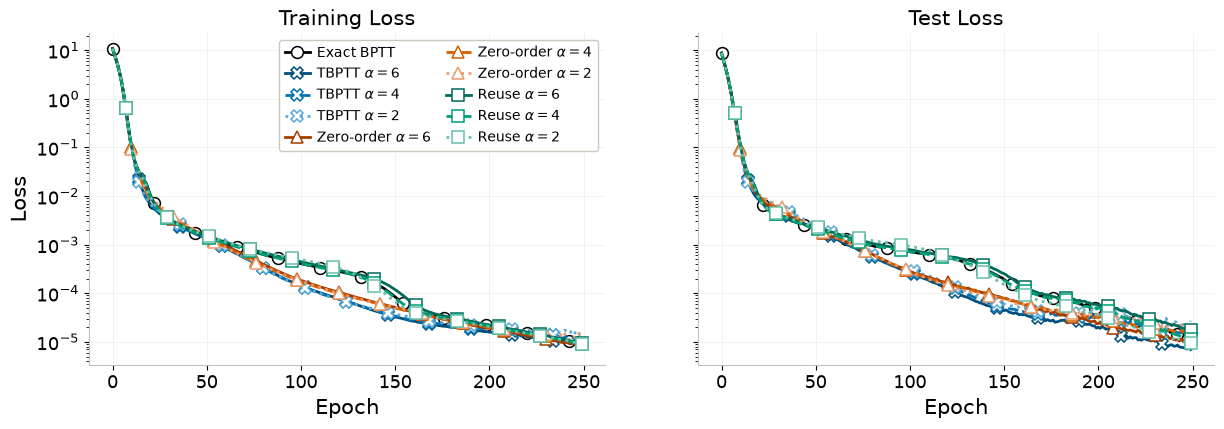

In [ ]:
# ============================================================
# TRAIN / TEST LOSS PLOT 

xlabel_size = 15
ylabel_size = 15
title_size = 15
ticklabel_size = 13
legend_size = 10

linewidth = 2.0
markersize = 9
markeredgewidth = 1.1

EXACT_LINEWIDTH_BOOST = 0.0
EXACT_MARKERSIZE_BOOST = -0.5
EXACT_MARKEREDGEWIDTH_BOOST = 0.0

markevery = 22   

BLACK = "#000000"

TBPTT_A6 = "#004F7C"
TBPTT_A4 = "#0072B2"
TBPTT_A2 = "#5AA9D6"

ZO_A6 = "#A63D00"
ZO_A4 = "#D55E00"
ZO_A2 = "#E99A6A"

REUSE_A6 = "#006B5B"
REUSE_A4 = "#009E73"
REUSE_A2 = "#66BFA8"

MARKER_METHOD = {
    "exact": "o",
    "tbptt": "X",
    "zo":    "^",
    "reuse": "s",
}

LINESTYLE_A = {6: "-", 4: "--", 2: ":"}

MARKER_OFFSET_METHOD = {
    "exact": 0,
    "tbptt": 14,
    "zo":    10,
    "reuse": 7,
}


runs = [
    (history_exact, "exact", 6, BLACK, "Exact BPTT"),   # A irrelevant for exact -> always solid

    (history_tbptt_A6, "tbptt", 6, TBPTT_A6, r"TBPTT $\alpha=6$"),
    (history_tbptt_A4, "tbptt", 4, TBPTT_A4, r"TBPTT $\alpha=4$"),
    (history_tbptt_A2, "tbptt", 2, TBPTT_A2, r"TBPTT $\alpha=2$"),

    (history_zo_A6, "zo", 6, ZO_A6, r"Zero-order $\alpha=6$"),
    (history_zo_A4, "zo", 4, ZO_A4, r"Zero-order $\alpha=4$"),
    (history_zo_A2, "zo", 2, ZO_A2, r"Zero-order $\alpha=2$"),

    (history_reuse_A6, "reuse", 6, REUSE_A6, r"Reuse $\alpha=6$"),
    (history_reuse_A4, "reuse", 4, REUSE_A4, r"Reuse $\alpha=4$"),
    (history_reuse_A2, "reuse", 2, REUSE_A2, r"Reuse $\alpha=2$"),
]


# FIGURE

fig, (ax_train, ax_test) = plt.subplots(
    1, 2, figsize=(12.5, 4.6), sharey=True,
)
fig.patch.set_facecolor("white")

for ax in (ax_train, ax_test):
    ax.set_facecolor("white")
    ax.grid(True, linestyle="-", linewidth=0.6, color="#e1e0d9", alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#c3c2b7")
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(axis="both", labelsize=ticklabel_size)
    ax.set_yscale("log")

for history, method, A, color, label in runs:

    is_exact = (method == "exact")
    marker = MARKER_METHOD[method]
    ls = "-" if is_exact else LINESTYLE_A[A]
    offset = MARKER_OFFSET_METHOD[method]

    lw = linewidth + EXACT_LINEWIDTH_BOOST if is_exact else linewidth
    ms = markersize + EXACT_MARKERSIZE_BOOST if is_exact else markersize
    mew = markeredgewidth + EXACT_MARKEREDGEWIDTH_BOOST if is_exact else markeredgewidth

    this_markevery = (offset, markevery)

    ax_train.plot(
        history["train_loss"],
        color=color, linestyle=ls, linewidth=lw,
        marker=marker, markersize=ms,
        markerfacecolor="white", markeredgecolor=color, markeredgewidth=mew,
        markevery=this_markevery,
        label=label,
        zorder=2 if is_exact else 3,
    )

    ax_test.plot(
        history["test_loss"],
        color=color, linestyle=ls, linewidth=lw,
        marker=marker, markersize=ms,
        markerfacecolor="white", markeredgecolor=color, markeredgewidth=mew,
        markevery=this_markevery,
        label="_nolegend_",
        zorder=2 if is_exact else 3,
    )

ax_train.set_title("Training Loss", fontsize=title_size)
ax_test.set_title("Test Loss", fontsize=title_size)
ax_train.set_xlabel("Epoch", fontsize=xlabel_size)
ax_test.set_xlabel("Epoch", fontsize=xlabel_size)
ax_train.set_ylabel("Loss", fontsize=ylabel_size)


handles, labels = ax_train.get_legend_handles_labels()

leg = ax_train.legend(
    handles, labels,
    fontsize=legend_size, frameon=True, framealpha=0.9,
    edgecolor="#c3c2b7", facecolor="white",
    loc="upper right", ncol=2,
    columnspacing=1.0, handletextpad=0.5, handlelength=1.8,
)
leg.get_frame().set_facecolor("white")

fig.subplots_adjust(
    left=0.08, right=0.98, top=0.88, bottom=0.16, wspace=0.18,
)

# save_plot_path = 'pyplots/gradient_methods_loss_curves_l63'
# fig.savefig(
#     f"{save_plot_path}.pdf",
#     bbox_inches="tight",
#     facecolor="white",
# )

plt.show()

In [16]:
exact = load_training_runs("exact")
tbptt = load_training_runs("tbptt")
zo = load_training_runs("zero_order")
reuse = load_training_runs("reuse")

trained_params_by_method = {
    "EXACT": exact["runs"][1]["params"],          
    "TBPTT (A=6)": tbptt["runs"][6]["params"],
    "TBPTT (A=4)": tbptt["runs"][4]["params"],
    "TBPTT (A=2)": tbptt["runs"][2]["params"],
    "ZO (A=6)": zo["runs"][6]["params"],
    "ZO (A=4)": zo["runs"][4]["params"],
    "ZO (A=2)": zo["runs"][2]["params"],
    "REUSE (A=6)": reuse["runs"][6]["params"],
    "REUSE (A=4)": reuse["runs"][4]["params"],
    "REUSE (A=2)": reuse["runs"][2]["params"],
}

corrected_trajs = {
    name: rollout(step_fn_hybrid_l63, state0, tp, nsteps=1000, save_traj=True)[1]
    for name, tp in trained_params_by_method.items()
}

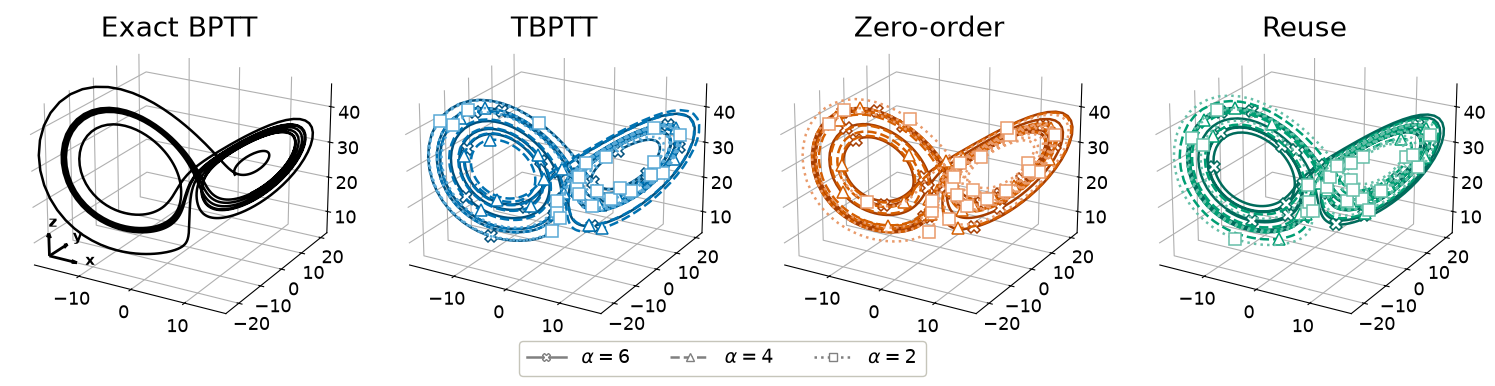

In [ ]:
# ============================================================
# L63 TRAJECTORIES -- 4 PANELS (Exact BPTT / TBPTT / Zero-order / Reuse)
# ============================================================

traj_groups = {
    "Exact BPTT": {
        "Exact BPTT": corrected_trajs["EXACT"],
    },
    "TBPTT": {
        6: corrected_trajs["TBPTT (A=6)"],
        4: corrected_trajs["TBPTT (A=4)"],
        2: corrected_trajs["TBPTT (A=2)"],
    },
    "Zero-order": {
        6: corrected_trajs["ZO (A=6)"],
        4: corrected_trajs["ZO (A=4)"],
        2: corrected_trajs["ZO (A=2)"],
    },
    "Reuse": {
        6: corrected_trajs["REUSE (A=6)"],
        4: corrected_trajs["REUSE (A=4)"],
        2: corrected_trajs["REUSE (A=2)"],
    },
}

BLACK = "#000000"

METHOD_COLORS = {
    "TBPTT":      {6: "#004F7C", 4: "#0072B2", 2: "#5AA9D6"},
    "Zero-order": {6: "#A63D00", 4: "#D55E00", 2: "#E99A6A"},
    "Reuse":      {6: "#006B5B", 4: "#009E73", 2: "#66BFA8"},
}

MARKER_A = {6: "X", 4: "^", 2: "s"}
LINESTYLE_A = {6: "-", 4: "--", 2: ":"}
MARKER_OFFSET_A = {6: 5, 4: 3, 2: 1}

LINEWIDTH = 1.8
MARKERSIZE = 8
MARKEREDGEWIDTH = 1.1
MARKEVERY = 45

EXACT_LINEWIDTH = 1.8

TITLE_SIZE = 20
TICK_SIZE = 13      
LEGEND_SIZE = 14
AXIS_LABEL_SIZE = 11   # used for the x/y/z triad labels

fig = plt.figure(figsize=(15.4, 4.0))

axes = [
    fig.add_subplot(1, 4, i + 1, projection="3d")
    for i in range(4)
]

all_pts = np.concatenate(list(corrected_trajs.values()), axis=0)
xmin, ymin, zmin = all_pts.min(axis=0)
xmax, ymax, zmax = all_pts.max(axis=0)

for ax, (method, trajs) in zip(axes, traj_groups.items()):

    if method == "Exact BPTT":

        traj = trajs["Exact BPTT"]

        ax.plot(
            traj[:, 0], traj[:, 1], traj[:, 2],
            color=BLACK, lw=EXACT_LINEWIDTH,
        )

    else:

        for A in [6, 4, 2]:

            traj = trajs[A]

            ax.plot(
                traj[:, 0], traj[:, 1], traj[:, 2],
                color=METHOD_COLORS[method][A],
                lw=LINEWIDTH,
                linestyle=LINESTYLE_A[A],
                marker=MARKER_A[A],
                markevery=(MARKER_OFFSET_A[A], MARKEVERY),
                markersize=MARKERSIZE,
                markerfacecolor="white",
                markeredgecolor=METHOD_COLORS[method][A],
                markeredgewidth=MARKEREDGEWIDTH,
            )

    ax.set_title(method, fontsize=TITLE_SIZE, y=0.974)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_zlim(zmin, zmax)

    ax.view_init(elev=22, azim=-60)

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_zlabel("")

    ax.tick_params(labelsize=TICK_SIZE, pad=0)

    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False

    ax.xaxis.pane.set_edgecolor("white")
    ax.yaxis.pane.set_edgecolor("white")
    ax.zaxis.pane.set_edgecolor("white")

# True 3D Coordinate Triad
triad_x = xmax - (xmax - xmin) * 0.95
triad_y = ymin + (ymax - ymin) * 0.05
triad_z = zmin + (zmax - zmin) * 0.05

arrow_len_x = (xmax - xmin) * 0.15
arrow_len_y = (ymax - ymin) * 0.15
arrow_len_z = (zmax - zmin) * 0.15

axes[0].quiver(triad_x, triad_y, triad_z, arrow_len_x, 0, 0, color="black", lw=2, arrow_length_ratio=0.2)
axes[0].quiver(triad_x, triad_y, triad_z, 0, arrow_len_y, 0, color="black", lw=2, arrow_length_ratio=0.2)
axes[0].quiver(triad_x, triad_y, triad_z, 0, 0, arrow_len_z, color="black", lw=2, arrow_length_ratio=0.2)

axes[0].text(triad_x + arrow_len_x * 1.3, triad_y, triad_z, "x", color="black", fontsize=AXIS_LABEL_SIZE, weight="bold")
axes[0].text(triad_x, triad_y + arrow_len_y * 1.3, triad_z, "y", color="black", fontsize=AXIS_LABEL_SIZE, weight="bold")
axes[0].text(triad_x, triad_y, triad_z + arrow_len_z * 1.3, "z", color="black", fontsize=AXIS_LABEL_SIZE, weight="bold")

# ------------------------------------------------------------------
# Legend -- one shared legend covering alpha=6/4/2. Placed via a FIGURE-
# level legend (fig.legend, not axes[0].legend) so its position is in
# whole-figure coordinates (0,0)=bottom-left, (1,1)=top-right of the
# ENTIRE figure -- easier to reason about and move than axes-relative
# coords buried inside one 3D subplot. Edit LEGEND_X / LEGEND_Y below
# to reposition; values slightly outside [0,1] are fine (e.g. -0.02
# nudges it just past the figure edge).
# ------------------------------------------------------------------

legend_handles = [
    Line2D([0], [0], color="gray", lw=LINEWIDTH, linestyle=LINESTYLE_A[6],
           marker=MARKER_A[6], markersize=6, markerfacecolor="white", label=r"$\alpha = 6$"),
    Line2D([0], [0], color="gray", lw=LINEWIDTH, linestyle=LINESTYLE_A[4],
           marker=MARKER_A[4], markersize=6, markerfacecolor="white", label=r"$\alpha = 4$"),
    Line2D([0], [0], color="gray", lw=LINEWIDTH, linestyle=LINESTYLE_A[2],
           marker=MARKER_A[2], markersize=6, markerfacecolor="white", label=r"$\alpha = 2$"),
]

LEGEND_X = 0.5    # 0 = left edge of figure, 1 = right edge
LEGEND_Y = 0.025    # 0 = bottom edge of figure, 1 = top edge

leg = fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(LEGEND_X, LEGEND_Y),
    ncol=3,
    fontsize=LEGEND_SIZE,
    frameon=True,
    framealpha=0.95,
    edgecolor="#c3c2b7",
    facecolor="white",
)

# Layout -- bottom margin widened slightly to leave room for the
# figure-level legend below the panels.
plt.subplots_adjust(
    left=0.03,
    right=0.995,
    top=0.965,
    bottom=0.12,
    wspace=0.04,
)

save_plot_path = 'pyplots/gradient_methods_l63_trajectories'
fig.savefig(
    f"{save_plot_path}.pdf",
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    f"{save_plot_path}.png",
    bbox_inches="tight",
    facecolor="white",
)

plt.show()